# 09 学習済み Fashion-MNIST MLP：第1 Linear のtensorization比較

08では、固定した3-core tensorizationに対してTT-rankをsweepし、Pareto frontierのkneeと前後1点からaggressive／balanced／conservativeの3候補を選びました。

このNotebookでは、その3候補の`fc1` parameter数を**基準予算**として、少数の3-core tensorizationを公平に比較します。比較対象ごとに、予算を超えない最大のTT parameter数となるrankを選び、同じrank-selection validationでweight誤差、validation accuracy、prediction agreement、logits RMSEを測ります。

ここではfine-tuningとtest評価を行いません。tensorizationの比較と、次へ渡す候補の選択までで止めます。

主要な実装はTODOとして残しています。関数の引数・戻り値・確認条件を読み、自分で実装してください。実装後に`EXERCISES_COMPLETED = True`へ変更し、Restart Kernel → Run Allで確認します。

In [1]:
# ============================================================
# import とプロジェクトルートの解決
# ============================================================
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

from nn_compression.compression import (
    TTLinear,
    dense_to_tt_matrix_tensor,
    factorize_named_tt_linear,
    ordered_factorizations,
    sweep_tt_matrix_weight_ranks,
    tt_matrix_physical_sizes,
    tt_matrix_shape_imbalance,
    tt_svd_error_bound,
)
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    make_fashion_mnist_loaders,
    split_fashion_mnist_dataset,
)
from nn_compression.metrics import (
    accuracy_drop,
    agreement,
    count_parameters,
    logits_rmse,
)
from nn_compression.models import MNISTMLP
from nn_compression.training import evaluate
from nn_compression.utils import find_project_root, make_torch_generator, set_seed

In [2]:
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
TARGET_LAYER = "fc1"
NUM_CORES = 3
RANK_GRID = [1, 2, 4, 8, 12, 16, 24, 32, 36, 48, 50, 64, 96, 128]
RANK_VALIDATION_BATCH_SIZE = 512
SAVE_RESULTS = True

# TODOをすべて実装し終えたらTrueへ変更する。
EXERCISES_COMPLETED = True

set_seed(SEED)
project_root = find_project_root(Path.cwd())
data_dir = project_root / "data"
checkpoint_path = (
    project_root / "models" / "10_svd" / "20_fashion_mnist_mlp"
    / "03_mlp_svd_finetuning_using_src_corrected_rerun"
    / "baseline_same_run.pt"
)
selection_path_08 = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "08_pretrained_mlp_fc1_tt_rank_sweep"
    / "selected_rank_candidates.csv"
)
results_dir = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "09_pretrained_mlp_fc1_tt_tensorization_comparison"
)

# 08のtensorization、その逆順、および別の因数分解を比較する。
TENSORIZATION_CANDIDATES = (
    {
        "tensorization": "reference_08",
        "out_modes": (2, 8, 32),
        "in_modes": (49, 8, 2),
    },
    {
        "tensorization": "reversed_sites",
        "out_modes": (32, 8, 2),
        "in_modes": (2, 8, 49),
    },
    {
        "tensorization": "eight_by_eight",
        "out_modes": (8, 8, 8),
        "in_modes": (7, 14, 8),
    },
)

assert checkpoint_path.is_file(), checkpoint_path
print("device:", DEVICE)
print("08 selection file exists:", selection_path_08.is_file())
print("exercises completed:", EXERCISES_COMPLETED)

device: cuda
08 selection file exists: True
exercises completed: True


## 1. Parameter予算を揃える理由

3-core TT-matrixで各siteのphysical sizeを$q_k=m_kn_k$、TT-rankを$(1,r_1,r_2,1)$とすると、coreのparameter数は

$$
P_{\mathrm{core}}=q_1r_1+r_1q_2r_2+r_2q_3
$$

です。同じrequested rankでも、tensorizationにより$q_k$が変わるためparameter数は一致しません。そのため、tensorization間でrequested rankを直接揃えるのではなく、08で選んだ`fc1` parameter数以下に揃えます。

例えば08のtensorizationでは$(q_1,q_2,q_3)=(98,64,64)$です。$(1,16,16,1)$なら、coreと512要素のbiasを合わせて

$$
98\times16+16\times64\times16+16\times64+512=19{,}488
$$

parameterです。09では、このような08側の実測parameter数を基準予算として使います。

In [3]:
# 既存APIで候補が正しい3因子分解か確認し、shape情報を可視化する。
valid_out_modes = set(ordered_factorizations(512, NUM_CORES))
valid_in_modes = set(ordered_factorizations(784, NUM_CORES))
candidate_rows = []

for candidate in TENSORIZATION_CANDIDATES:
    out_modes = candidate["out_modes"]
    in_modes = candidate["in_modes"]
    assert out_modes in valid_out_modes
    assert in_modes in valid_in_modes
    assert math.prod(out_modes) == 512
    assert math.prod(in_modes) == 784

    candidate_rows.append({
        **candidate,
        "physical_sizes": tt_matrix_physical_sizes(out_modes, in_modes),
        "shape_imbalance": tt_matrix_shape_imbalance(out_modes, in_modes),
    })

df_tensorizations = pd.DataFrame(candidate_rows)
display(df_tensorizations)

,tensorization,out_modes,in_modes,physical_sizes,shape_imbalance
0,reference_08,"(2, 8, 32)","(49, 8, 2)","(98, 64, 64)",1.53125
1,reversed_sites,"(32, 8, 2)","(2, 8, 49)","(64, 64, 98)",1.53125
2,eight_by_eight,"(8, 8, 8)","(7, 14, 8)","(56, 112, 64)",2.00000


## 2. 08からrank候補とparameter予算を受け取る

08を`SAVE_RESULTS=True`で実行すると、`selected_rank_candidates.csv`へaggressive／balanced／conservativeの3候補が保存されます。09は、このCSVの`fc1_parameters`を基準予算として使います。

test setの情報は読み込みません。08のrank選択と09のtensorization選択は、同じrank-selection validationだけで行います。

In [4]:
def load_selected_parameter_budgets(selection_csv: Path) -> pd.DataFrame:
    """08が保存したrank候補から、09で使うparameter予算を読み込む。

    Args:
        selection_csv: 08の``selected_rank_candidates.csv``へのパス。

    Returns:
        aggressive、balanced、conservativeの順に並んだDataFrame。
        ``selection_role``、``requested_rank``、``fc1_parameters``を含む。

    Raises:
        FileNotFoundError: 08の選択結果が保存されていない場合。
        ValueError: 必須列・role・parameter予算に不整合がある場合。
    """
    if not selection_csv.is_file():
        raise FileNotFoundError(
            "08をSAVE_RESULTS=Trueで実行し、選択候補CSVを保存してください: "
            f"{selection_csv}"
        )

    selected = pd.read_csv(selection_csv)
    required_columns = {
        "selection_role", "requested_rank", "fc1_parameters"
    }
    missing = required_columns.difference(selected.columns)
    if missing:
        raise ValueError(f"08の選択CSVに必須列がありません: {sorted(missing)}")

    role_order = ["aggressive", "balanced", "conservative"]
    if set(selected["selection_role"]) != set(role_order):
        raise ValueError(
            "selection_roleはaggressive / balanced / conservativeの3件が必要です。"
        )
    if selected["selection_role"].duplicated().any():
        raise ValueError("selection_roleが重複しています。")
    if (selected["fc1_parameters"] <= 0).any():
        raise ValueError("fc1 parameter予算は正である必要があります。")

    selected = selected.copy()
    selected["selection_role"] = pd.Categorical(
        selected["selection_role"], categories=role_order, ordered=True
    )
    return selected.sort_values("selection_role").reset_index(drop=True)


if EXERCISES_COMPLETED:
    df_budgets_08 = load_selected_parameter_budgets(selection_path_08)
    display(df_budgets_08[[
        "selection_role", "requested_rank", "fc1_parameters",
        "validation_accuracy", "prediction_agreement",
    ]])
else:
    print("TODO実装後に08の選択結果を読み込みます。")

,selection_role,requested_rank,fc1_parameters,validation_accuracy,prediction_agreement
0,aggressive,16,19488,0.3978,0.3990
1,balanced,32,71232,0.7556,0.7976
2,conservative,64,273024,0.8736,0.9558


## 3. 08と同じbaseline・validation splitを再構成する

データ準備とcheckpoint読み込みは08で確認済みなので完成コードです。50,000／5,000／5,000の3番目だけをtensorization選択に使います。shuffle付きのtrain loaderは評価に使いません。

In [5]:
if EXERCISES_COMPLETED:
    full_train_dataset, test_dataset = get_fashion_mnist_datasets(
        data_dir, download=True
    )
    train_dataset, early_stopping_dataset, rank_validation_dataset = (
        split_fashion_mnist_dataset(
            full_train_dataset, (50_000, 5_000, 5_000), seed=SEED
        )
    )
    loaders = make_fashion_mnist_loaders(
        train_dataset,
        early_stopping_dataset,
        test_dataset,
        train_batch_size=64,
        validation_batch_size=RANK_VALIDATION_BATCH_SIZE,
        test_batch_size=1000,
        rank_validation_dataset=rank_validation_dataset,
        train_generator=make_torch_generator(SEED),
    )
    rank_validation_loader = loaders["validation_loader_rank"]

    baseline_model = MNISTMLP().to(device=DEVICE, dtype=DTYPE)
    baseline_state = torch.load(
        checkpoint_path, map_location=DEVICE, weights_only=True
    )
    baseline_model.load_state_dict(baseline_state)
    baseline_model.eval()

    baseline_loss, baseline_accuracy = evaluate(
        baseline_model, rank_validation_loader, torch.nn.CrossEntropyLoss(), DEVICE
    )
    baseline_parameters = count_parameters(baseline_model)
    fc1_bias_parameters = (
        0 if baseline_model.fc1.bias is None else baseline_model.fc1.bias.numel()
    )

    assert len(rank_validation_loader.dataset) == 5_000
    assert baseline_model.fc1.weight.shape == (512, 784)
    print(f"baseline validation accuracy: {baseline_accuracy:.4f}")
else:
    print("データ取得とbaseline評価はTODO実装後に実行します。")

baseline validation accuracy: 0.8884


## 4. TODO 1：各tensorizationのweight rank sweepを作る

### このセルで実装すること

`sweep_tt_matrix_weight_ranks`を各tensorizationへ適用し、既存APIが返すrecordへtensorization名、modes、physical sizes、bias込みの`fc1_parameters`を追加して1つのDataFrameにまとめます。TT-SVDや再構成誤差をNotebook内で再実装しません。

### 期待する検証結果

- 行数が`tensorization候補数 × rank候補数`と一致する
- 各候補の`out_modes`と`in_modes`の積が512と784になる
- `fc1_parameters == tt_parameters + bias parameter数`になる
- `relative_error`が非負になる

In [6]:
def build_tensorization_weight_sweep(
    weight: torch.Tensor,
    tensorizations: pd.DataFrame,
    requested_ranks: list[int],
    *,
    bias_parameters: int,
) -> pd.DataFrame:
    """複数tensorizationのTT weight rank sweepを1表へまとめる。

    Args:
        weight: TT近似するdense Linear weight。shapeは``(512, 784)``。
        tensorizations: ``tensorization``、``out_modes``、``in_modes``、
            ``physical_sizes``を持つ比較候補表。
        requested_ranks: 各bondへ共通に指定するrank上限の候補。
        bias_parameters: ``fc1_parameters``へ加えるbias要素数。

    Returns:
        既存rank sweepの各recordへtensorization情報とbias込みの
        ``fc1_parameters``を加えたDataFrame。
    """
    # TODO 1: tensorizationごとに既存APIを呼び、recordを連結する。
    columns = ["tensorization", "out_modes", "in_modes", "physical_sizes"]
    all_rows = []
    for tensorization, out_modes, in_modes, physical_sizes in (
        tensorizations[columns].itertuples(index=False, name=None)
    ):
        records = sweep_tt_matrix_weight_ranks(
            weight, out_modes, in_modes, requested_ranks
        )
        for record in records:
            row = {
                **record,
                "tensorization": tensorization,
                "out_modes": out_modes,
                "in_modes": in_modes,
                "physical_sizes": physical_sizes,
                "fc1_parameters": record["tt_parameters"] + bias_parameters,
            }
            all_rows.append(row)
    return pd.DataFrame(all_rows)

if EXERCISES_COMPLETED:
    # TODO 1-1: 上で実装した関数を必要な引数で呼び出す。
    df_weight_sweeps = build_tensorization_weight_sweep(
        baseline_model.fc1.weight,  # 圧縮対象の重み
        df_tensorizations,  # tensorization候補の表
        RANK_GRID,  # 試すrankのリスト
        bias_parameters=fc1_bias_parameters,
    )
    # TODO 1-2: 行数、誤差の非負性、bias込みparameter数を検証する。
    assert len(df_weight_sweeps) == len(df_tensorizations) * len(RANK_GRID)
    assert (df_weight_sweeps["relative_error"] >= 0).all()
    assert (
        df_weight_sweeps["fc1_parameters"]
        == df_weight_sweeps["tt_parameters"] + fc1_bias_parameters
    ).all()
    # TODO 1-3: 比較に必要な列を表示して内容を確認する。
    columns_to_show = [
        "tensorization",
        "requested_rank",
        "actual_ranks",
        "fc1_parameters",
        "relative_error",
    ]

    display(df_weight_sweeps[columns_to_show])

,tensorization,requested_rank,actual_ranks,fc1_parameters,relative_error
0,reference_08,1,"(1, 1, 1, 1)",738,0.986781
1,reference_08,2,"(1, 2, 2, 1)",1092,0.983459
2,reference_08,4,"(1, 4, 4, 1)",2184,0.974299
3,reference_08,8,"(1, 8, 8, 1)",5904,0.948044
4,reference_08,12,"(1, 12, 12, 1)",11672,0.914766
5,reference_08,16,"(1, 16, 16, 1)",19488,0.877227
6,reference_08,24,"(1, 24, 24, 1)",41264,0.793180
7,reference_08,32,"(1, 32, 32, 1)",71232,0.707556
8,reference_08,36,"(1, 36, 36, 1)",89288,0.668139
9,reference_08,48,"(1, 48, 48, 1)",155744,0.550463


## 5. TODO 2：各予算以下になるrankを選ぶ

### このセルで実装すること

1つのtensorizationのsweep結果から、`fc1_parameters`が基準予算以下の行だけを残し、その中でparameter数が最大の行を返します。同じparameter数の行が複数ある場合は、relative weight errorが小さい方を選びます。

ここで揃えるのはrequested rankではなく、実際のTT coreとbiasが保持するparameter数です。

### 期待する検証結果

- 選択された`fc1_parameters`が基準予算を超えない
- 各roleと各tensorizationについて1行ずつ選ばれる
- 08のreference tensorizationでは、08で選んだrankが再現される

In [7]:
def select_rank_under_budget(
    tensorization_sweep: pd.DataFrame,
    fc1_parameter_budget: int,
) -> pd.Series:
    """1つのtensorizationからparameter予算内の最大構成を選ぶ。

    Args:
        tensorization_sweep: 1つのtensorizationだけを含むweight sweep表。
        fc1_parameter_budget: TT coresとbiasに許すparameter数の上限。

    Returns:
        予算以下で``fc1_parameters``が最大の1行。同数の場合は
        ``relative_error``が小さい行。

    Raises:
        ValueError: 表が空、複数tensorizationを含む、または予算内候補がない場合。
    """
    # TODO 2: 入力を検証し、予算内候補を並べ替えて1行返す。

    # 前提チェック1: 空の表は選べない
    if tensorization_sweep.empty:
        raise ValueError("tensorization_sweep が空です。")

    # 前提チェック2: この関数は「1つの tensorization」専用
    # （複数混ざっていると予算比較の意味が壊れる）
    if tensorization_sweep["tensorization"].nunique() != 1:
        raise ValueError("複数の tensorization が含まれています。")

    # 予算以内の行だけ残す（fc1_parameters = TT cores + bias）
    within_budget = tensorization_sweep.loc[
        tensorization_sweep["fc1_parameters"] <= fc1_parameter_budget
    ]

    # 前提チェック3: 予算が厳しすぎて1行も残らない場合
    if within_budget.empty:
        raise ValueError("予算内の候補がありません。")

    # 並べ替え:
    # 1) fc1_parameters が大きいほどよい（降順）
    # 2) 同点なら relative_error が小さいほどよい（昇順）
    sorted_candidates = within_budget.sort_values(
        by=["fc1_parameters", "relative_error"],
        ascending=[False, True],
    )

    # 先頭1行が「予算内で最大の構成」
    return sorted_candidates.iloc[0]

if EXERCISES_COMPLETED:
    # TODO 2-1: role×tensorization の全組合せを走査する。
    # - role: df_budgets_08 の aggressive / balanced / conservative
    # - tensorization: df_tensorizations の各 modes 候補
    budget_match_records = []

    for budget_row in df_budgets_08.itertuples(index=False):
        for tensorization_row in df_tensorizations.itertuples(index=False):
            # TODO 2-2: 各組合せで予算以下のrankを選び、比較用recordを作る。

            # この tensorization だけの sweep 行を取り出す
            candidate_sweep = df_weight_sweeps.loc[
                df_weight_sweeps["tensorization"] == tensorization_row.tensorization
            ]

            # この role の fc1 予算以下で、最大構成（同点なら誤差最小）を1行選ぶ
            selected_row = select_rank_under_budget(
                candidate_sweep,
                int(budget_row.fc1_parameters),
            )

            # 選ばれた構成 + 08側の参照情報を1 record にまとめる
            record = selected_row.to_dict()
            record["selection_role"] = budget_row.selection_role
            # 08で選ばれていた requested rank（reference_08 の再現確認用）
            record["reference_requested_rank_08"] = int(
                budget_row.requested_rank
            )
            # この role の基準予算（選んだ fc1_parameters と比較する上限）
            record["reference_fc1_parameter_budget"] = int(
                budget_row.fc1_parameters
            )
            budget_match_records.append(record)

    # 二重ループの外: 全組合せの record を1つの表にする
    df_budget_matches = pd.DataFrame(budget_match_records)
    print("budget matches rows:", len(df_budget_matches))
    print(df_budget_matches.round(6))

    # TODO 2-3: 行数、予算上限、reference rankの再現を検証する。
    expected_rows = len(df_budgets_08) * len(df_tensorizations)
    assert len(df_budget_matches) == expected_rows
    assert (
        df_budget_matches["fc1_parameters"]
        <= df_budget_matches["reference_fc1_parameter_budget"]
    ).all()

    reference_rows = df_budget_matches.loc[
        df_budget_matches["tensorization"] == "reference_08"
    ]
    assert len(reference_rows) == len(df_budgets_08)
    reference_rank_by_role = (
        reference_rows.set_index("selection_role")["requested_rank"]
        .astype(int)
        .to_dict()
    )
    expected_rank_by_role = (
        df_budgets_08.set_index("selection_role")["requested_rank"]
        .astype(int)
        .to_dict()
    )
    assert reference_rank_by_role == expected_rank_by_role

budget matches rows: 9
   requested_rank    actual_ranks  tt_parameters  dense_parameters  \
0              16  (1, 16, 16, 1)          18976            401408   
1              16  (1, 16, 16, 1)          18976            401408   
2              12  (1, 12, 12, 1)          17568            401408   
3              32  (1, 32, 32, 1)          70720            401408   
4              32  (1, 32, 32, 1)          70720            401408   
5              24  (1, 24, 24, 1)          67392            401408   
6              64  (1, 64, 64, 1)         272512            401408   
7              64  (1, 64, 64, 1)         272512            401408   
8              48  (1, 48, 48, 1)         263808            401408   

   compression_ratio  absolute_error  relative_error  is_compressed  \
0          21.153457       41.455432        0.877227           True   
1          21.153457       39.839674        0.843037           True   
2          22.848816       41.496062        0.878087           

## 6. TT-SVD各cutの特異値エネルギーを診断する

同じrankでもtensorizationによって逐次TT-SVDが処理する行列が変わるため、上位特異値に残るエネルギーも変わります。各cutで、

$$
\eta_k
=
\frac{\sum_{j=1}^{r_k}\left(\sigma_j^{(k)}\right)^2}{\sum_j\left(\sigma_j^{(k)}\right)^2}
=
1-\frac{\left(\delta_k\right)^2}{\left\|R_k\right\|_F^2}
$$

を計算します。$R_k$はTT-SVDの第$k$段階へ入るremainder、$\delta_k$はその段階で捨てる特異値の2乗和平方根です。

この診断は完成コードです。SVDを再実装せず、既存の`dense_to_tt_matrix_tensor`と`tt_svd_error_bound`を使います。後者は実際の逐次TT-SVDと同じremainder更新を行うため、元テンソルを単独でunfoldした値ではなく、各段階で実際に捨てるエネルギーを確認できます。

,selection_role,tensorization,requested_rank,cut_1_retained_energy,cut_2_retained_energy,global_retained_energy_ratio,relative_error
0,aggressive,reference_08,16,0.382773,0.602085,0.230462,0.877227
1,aggressive,reversed_sites,16,0.410367,0.704936,0.289282,0.843037
2,aggressive,eight_by_eight,12,0.396149,0.577959,0.228958,0.878087
3,balanced,reference_08,32,0.597550,0.835674,0.499358,0.707556
4,balanced,reversed_sites,32,0.670071,0.823076,0.551520,0.669683
5,balanced,eight_by_eight,24,0.656561,0.779365,0.511701,0.698781
6,conservative,reference_08,64,0.857020,1.000000,0.857020,0.378123
7,conservative,reversed_sites,64,1.000000,0.934538,0.934538,0.255853
8,conservative,eight_by_eight,48,0.941917,0.945520,0.890602,0.330753


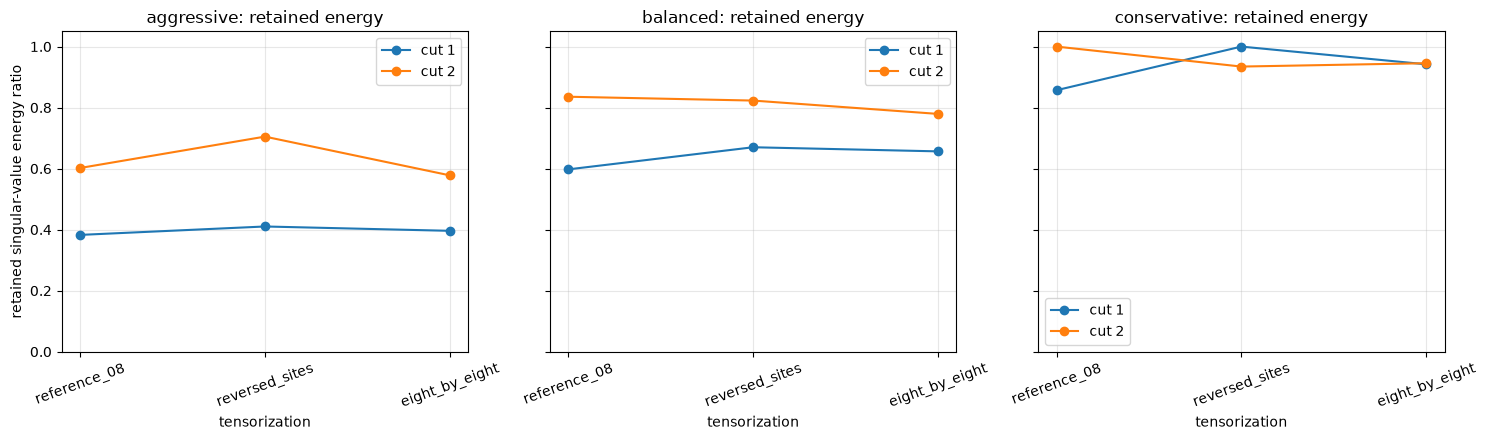

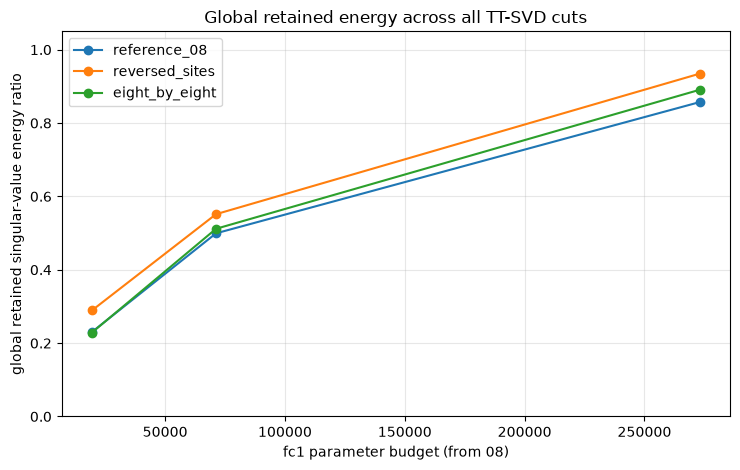

In [8]:
if EXERCISES_COMPLETED:
    cut_energy_records = []
    energy_summary_records = []

    for matched_row in df_budget_matches.itertuples(index=False):
        # 既存API: dense W -> combined tensor (q1,...,qd)
        combined_tensor = dense_to_tt_matrix_tensor(
            baseline_model.fc1.weight.detach(),
            tuple(matched_row.out_modes),
            tuple(matched_row.in_modes),
        )
        # 各 internal bond に同じ requested rank 上限を渡す
        requested_ranks = [
            int(matched_row.requested_rank)
        ] * (combined_tensor.ndim - 1)

        # 既存API: 逐次TT-SVDと同じ remainder 更新での各cut tail norm
        global_bound, local_tail_norms = tt_svd_error_bound(
            combined_tensor, requested_ranks
        )
        original_norm = float(torch.linalg.vector_norm(combined_tensor).item())
        current_energy = original_norm ** 2
        summary = {
            "selection_role": matched_row.selection_role,
            "tensorization": matched_row.tensorization,
            "requested_rank": int(matched_row.requested_rank),
            "tt_svd_relative_error_bound": (
                float(global_bound.item()) / original_norm
                if original_norm > 0.0 else 0.0
            ),
        }

        # actual_ranks = (1, r1, r2, 1) なので cut k は index k を使う
        actual_ranks = tuple(matched_row.actual_ranks)
        for cut_index, tail_norm in enumerate(local_tail_norms, start=1):
            discarded_energy = float(tail_norm.item()) ** 2
            discarded_ratio = (
                discarded_energy / current_energy
                if current_energy > 0.0 else 0.0
            )
            retained_ratio = 1.0 - discarded_ratio

            cut_energy_records.append({
                "selection_role": matched_row.selection_role,
                "tensorization": matched_row.tensorization,
                "requested_rank": int(matched_row.requested_rank),
                "cut": cut_index,
                "actual_rank": int(actual_ranks[cut_index]),
                "retained_energy_ratio": retained_ratio,
                "discarded_energy_ratio": discarded_ratio,
            })
            summary[f"cut_{cut_index}_retained_energy"] = retained_ratio
            summary[f"cut_{cut_index}_discarded_energy"] = discarded_ratio

            # 次段階へ渡るエネルギーを更新する
            current_energy = current_energy - discarded_energy

        energy_summary_records.append(summary)

    df_tt_svd_cut_energy = pd.DataFrame(cut_energy_records)
    df_tt_svd_energy_summary = pd.DataFrame(energy_summary_records)

    # 再実行時に merge で _x/_y が増えないよう、診断列を落としてから結合する
    diagnostic_columns = [
        column for column in df_tt_svd_energy_summary.columns
        if column not in {
            "selection_role", "tensorization", "requested_rank"
        }
    ]
    stale_merge_columns = [
        column for column in df_budget_matches.columns
        if column.endswith("_x") or column.endswith("_y")
    ]
    # 再計算前に旧 global 列も落としておく
    df_budget_matches = df_budget_matches.drop(
        columns=[
            *diagnostic_columns,
            *stale_merge_columns,
            "global_retained_energy_ratio",
        ],
        errors="ignore",
    ).merge(
        df_tt_svd_energy_summary,
        on=["selection_role", "tensorization", "requested_rank"],
        how="left",
        validate="one_to_one",
    )

    # retained + discarded = 1 を各cutで確認（dtypeを揃えて比較）
    energy_sum = (
        df_tt_svd_cut_energy["retained_energy_ratio"]
        + df_tt_svd_cut_energy["discarded_energy_ratio"]
    )
    energy_sum_tensor = torch.tensor(energy_sum.to_numpy())
    assert torch.allclose(
        energy_sum_tensor,
        torch.ones_like(energy_sum_tensor),
        rtol=1e-6,
        atol=1e-6,
    )
    # 実測 relative_error は TT-SVD relative bound 以下
    assert (
        df_budget_matches["relative_error"]
        <= df_budget_matches["tt_svd_relative_error_bound"] + 1e-5
    ).all()

    # 全cut統合の retained energy:
    # η_global = 1 - (tt_svd_relative_error_bound)^2 = η1 * η2
    df_budget_matches["global_retained_energy_ratio"] = (
        1.0 - df_budget_matches["tt_svd_relative_error_bound"] ** 2
    )
    global_energy = df_budget_matches["global_retained_energy_ratio"]
    product_energy = (
        df_budget_matches["cut_1_retained_energy"]
        * df_budget_matches["cut_2_retained_energy"]
    )
    assert global_energy.between(-1e-6, 1.0 + 1e-6).all()
    assert torch.allclose(
        torch.tensor(global_energy.to_numpy()),
        torch.tensor(product_energy.to_numpy()),
        rtol=1e-5,
        atol=1e-6,
    )

    display(df_budget_matches[[
        "selection_role",
        "tensorization",
        "requested_rank",
        "cut_1_retained_energy",
        "cut_2_retained_energy",
        "global_retained_energy_ratio",
        "relative_error",
    ]])

    # roleごとに cut1/cut2 の retained energy を tensorization 間で比較
    roles = ["aggressive", "balanced", "conservative"]
    tensorization_order = list(df_tensorizations["tensorization"])
    fig_energy, axes_energy = plt.subplots(
        1, len(roles), figsize=(15, 4.5), sharey=True
    )
    for ax, role in zip(axes_energy, roles):
        role_rows = df_tt_svd_cut_energy.loc[
            df_tt_svd_cut_energy["selection_role"] == role
        ].copy()
        role_rows["tensorization"] = pd.Categorical(
            role_rows["tensorization"],
            categories=tensorization_order,
            ordered=True,
        )
        for cut, group in role_rows.groupby("cut", sort=True):
            ordered = group.sort_values("tensorization")
            ax.plot(
                ordered["tensorization"].astype(str),
                ordered["retained_energy_ratio"],
                marker="o",
                label=f"cut {cut}",
            )
        # 1.0 の点が上端で切れないよう、表示だけ少し余白を取る
        ax.set_ylim(0.0, 1.05)
        ax.set_xlabel("tensorization")
        ax.set_title(f"{role}: retained energy")
        ax.tick_params(axis="x", rotation=20)
        ax.grid(True, alpha=0.3)
        ax.legend()
    axes_energy[0].set_ylabel("retained singular-value energy ratio")
    fig_energy.tight_layout()
    plt.show()

    # 全cut統合の retained energy（予算 vs tensorization）
    fig_global_energy, ax_global = plt.subplots(figsize=(7.5, 4.8))
    for tensorization, group in df_budget_matches.groupby(
        "tensorization", sort=False
    ):
        ordered = group.sort_values("reference_fc1_parameter_budget")
        ax_global.plot(
            ordered["reference_fc1_parameter_budget"],
            ordered["global_retained_energy_ratio"],
            marker="o",
            label=tensorization,
        )
    ax_global.set_ylim(0.0, 1.05)
    ax_global.set_xlabel("fc1 parameter budget (from 08)")
    ax_global.set_ylabel("global retained singular-value energy ratio")
    ax_global.set_title("Global retained energy across all TT-SVD cuts")
    ax_global.grid(True, alpha=0.3)
    ax_global.legend()
    fig_global_energy.tight_layout()
    plt.show()
else:
    print("特異値エネルギー診断はTODO 1〜2の実装後に実行します。")


## 7. TODO 3：予算を揃えたTTモデルをvalidationで評価する

### このセルで実装すること

選んだmodesとrankで、既存APIの`factorize_named_tt_linear`を使って`fc1`だけをTTLinearへ置換します。評価には既存の`evaluate`、`agreement`、`logits_rmse`、`count_parameters`、`accuracy_drop`を使います。これらをNotebook内で作り直しません。

### 期待する検証結果

- baselineの`fc1`は`torch.nn.Linear`のまま変化しない
- 圧縮モデルの`fc1`だけが`TTLinear`になる
- accuracyとagreementが0以上1以下になる
- logits RMSEが非負になる
- accuracyとagreementを同じ指標として扱わない

In [9]:
def evaluate_tensorization_candidate(
    baseline_model: torch.nn.Module,
    validation_loader: DataLoader,
    *,
    target_layer: str,
    out_modes: tuple[int, ...],
    in_modes: tuple[int, ...],
    requested_rank: int,
    baseline_accuracy: float,
    baseline_parameters: int,
    device: torch.device,
) -> dict[str, float | int]:
    """1つの予算調整済みtensorizationをvalidationで評価する。

    Args:
        baseline_model: checkpointを読み込んだdense MLP。変更してはいけない。
        validation_loader: rank・tensorization選択専用のDataLoader。
        target_layer: TTLinearへ置換する名前付きLinear層。
        out_modes: target層の出力次元を分解したmode列。
        in_modes: target層の入力次元を分解したmode列。
        requested_rank: 各internal bondへ指定する共通rank上限。
        baseline_accuracy: 同じvalidationにおけるdense baseline accuracy。
        baseline_parameters: dense baselineモデル全体のparameter数。
        device: forwardと評価を行う計算device。

    Returns:
        validation loss/accuracy、accuracy drop、prediction agreement、
        logits RMSE、model parameter数、model compression ratioを持つ辞書。
    """
    # TODO 3: 既存APIだけを組み合わせて圧縮モデルを生成・評価する。
    # baseline は変更せず、指定層だけ TTLinear に置換したコピーを作る
    compressed_model = factorize_named_tt_linear(
        baseline_model,
        target_layer,
        out_modes,
        in_modes,
        max_rank=requested_rank,
    )

    # 正解ラベル基準の分類性能（loss / accuracy）
    validation_loss, validation_accuracy = evaluate(
        compressed_model,
        validation_loader,
        torch.nn.CrossEntropyLoss(),
        device,
    )

    # dense accuracy からの低下量（正なら精度が落ちた）
    drop = accuracy_drop(
        baseline_accuracy,
        validation_accuracy,
        verbose=False,
    )

    # dense と圧縮モデルの予測クラス一致率（accuracy とは別指標）
    prediction_agreement = agreement(
        baseline_model,
        compressed_model,
        validation_loader,
        device,
    )

    # logits 全体のずれ（クラス一致より細かい誤差）
    rmse = logits_rmse(
        baseline_model,
        compressed_model,
        validation_loader,
        device,
    )

    # model全体の保存量と、baseline に対する圧縮率
    model_parameters = count_parameters(compressed_model)
    model_compression_ratio = baseline_parameters / model_parameters

    # docstringどおり返すキー
    return {
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
        "accuracy_drop": drop,
        "prediction_agreement": prediction_agreement,
        "logits_rmse": rmse,
        "model_parameters": model_parameters,
        "model_compression_ratio": model_compression_ratio,
    }


if EXERCISES_COMPLETED:
    # TODO 3-1: 評価前後で baseline.fc1 が書き換えられていないことを確認するため、
    # いまの weight を別テンソルとして保存する。
    baseline_fc1_weight_before = (
        baseline_model.fc1.weight.detach().clone()
    )

    # TODO 3-2: 予算調整済みの全構成（role × tensorization）を評価し、
    # weight sweep側の指標（relative_error など）と validation 指標を1行に結合する。
    comparison_records = []
    for matched_row in df_budget_matches.itertuples(index=False):
        metrics = evaluate_tensorization_candidate(
            baseline_model,
            rank_validation_loader,
            target_layer=TARGET_LAYER,
            out_modes=tuple(matched_row.out_modes),
            in_modes=tuple(matched_row.in_modes),
            requested_rank=int(matched_row.requested_rank),
            baseline_accuracy=baseline_accuracy,
            baseline_parameters=baseline_parameters,
            device=DEVICE,
        )
        # matched_row: 予算選択結果 / metrics: validation評価結果
        record = matched_row._asdict()
        record.update(metrics)
        # 予算に対して、実際に使った fc1 parameter の割合
        record["budget_utilization"] = (
            record["fc1_parameters"]
            / record["reference_fc1_parameter_budget"]
        )
        comparison_records.append(record)

    df_tensorization_comparison = pd.DataFrame(comparison_records)

    # TODO 3-3: accuracy、agreement、logits RMSEとモデル型を検証する。
    # baseline の weight / 型は評価後も元のまま
    assert torch.equal(
        baseline_model.fc1.weight,
        baseline_fc1_weight_before,
    )
    assert isinstance(baseline_model.fc1, torch.nn.Linear)

    # 圧縮側だけ TTLinear になること（代表1件で確認）
    probe_row = df_budget_matches.iloc[0]
    probe_model = factorize_named_tt_linear(
        baseline_model,
        TARGET_LAYER,
        tuple(probe_row.out_modes),
        tuple(probe_row.in_modes),
        max_rank=int(probe_row.requested_rank),
    )
    assert isinstance(probe_model.fc1, TTLinear)

    # 指標の値域チェック
    assert df_tensorization_comparison["validation_accuracy"].between(0.0, 1.0).all()
    assert df_tensorization_comparison["prediction_agreement"].between(0.0, 1.0).all()
    assert (df_tensorization_comparison["logits_rmse"] >= 0.0).all()

    display(df_tensorization_comparison[[
        "selection_role", "tensorization", "requested_rank",
        "fc1_parameters", "budget_utilization", "relative_error",
        "validation_accuracy", "prediction_agreement", "logits_rmse",
        "model_parameters",
    ]])



,selection_role,tensorization,requested_rank,fc1_parameters,budget_utilization,relative_error,validation_accuracy,prediction_agreement,logits_rmse,model_parameters
0,aggressive,reference_08,16,19488,1.000000,0.877227,0.3978,0.3990,8.465771,153386
1,aggressive,reversed_sites,16,19488,1.000000,0.843037,0.5116,0.5276,7.933703,153386
2,aggressive,eight_by_eight,12,18080,0.927750,0.878087,0.3290,0.3434,7.942345,151978
3,balanced,reference_08,32,71232,1.000000,0.707556,0.7556,0.7976,5.978704,205130
4,balanced,reversed_sites,32,71232,1.000000,0.669683,0.7980,0.8460,4.451787,205130
5,balanced,eight_by_eight,24,67904,0.953279,0.698781,0.7144,0.7570,4.483128,201802
6,conservative,reference_08,64,273024,1.000000,0.378123,0.8736,0.9558,1.586787,406922
7,conservative,reversed_sites,64,273024,1.000000,0.255853,0.8872,0.9922,0.179470,406922
8,conservative,eight_by_eight,48,264320,0.968120,0.330753,0.8812,0.9746,0.818977,398218


## 8. 各予算で次へ渡すtensorizationを選ぶ

各roleの予算内でvalidation accuracyが最大のtensorizationを選びます。同率ならmodel parameter数が少ない方、それも同じならrelative weight errorが小さい方を採用します。

この選択は完成コードです。tensorization比較の主要な学習対象は、TODO 1〜3の予算調整とTTモデル評価です。

In [10]:
if EXERCISES_COMPLETED:
    df_selected_tensorizations = (
        df_tensorization_comparison.sort_values(
            [
                "selection_role",
                "validation_accuracy",
                "model_parameters",
                "relative_error",
            ],
            ascending=[True, False, True, True],
        )
        .groupby("selection_role", observed=True, sort=False)
        .head(1)
        .reset_index(drop=True)
    )
    assert len(df_selected_tensorizations) == len(df_budgets_08)
    assert df_selected_tensorizations["selection_role"].nunique() == len(
        df_budgets_08
    )
    display(df_selected_tensorizations[[
        "selection_role", "tensorization", "out_modes", "in_modes",
        "requested_rank", "actual_ranks", "model_parameters",
        "validation_accuracy", "prediction_agreement",
    ]])
else:
    print("tensorizationの選択はTODO 1〜3の実装後に実行します。")

,selection_role,tensorization,out_modes,in_modes,requested_rank,actual_ranks,model_parameters,validation_accuracy,prediction_agreement
0,aggressive,reversed_sites,"(32, 8, 2)","(2, 8, 49)",16,"(1, 16, 16, 1)",153386,0.5116,0.5276
1,balanced,reversed_sites,"(32, 8, 2)","(2, 8, 49)",32,"(1, 32, 32, 1)",205130,0.7980,0.8460
2,conservative,reversed_sites,"(32, 8, 2)","(2, 8, 49)",64,"(1, 64, 64, 1)",406922,0.8872,0.9922


## 9. TODO 4：tensorization間のtrade-offを可視化する

`matplotlib`で横並び4図を作ります。横軸は08由来の`fc1` parameter予算、線はtensorizationごとに分けます。

1. relative Frobenius weight error
2. validation accuracy（dense baselineを黒い破線で表示）
3. prediction agreement（baseline accuracyの線は表示しない）
4. model compression ratio

accuracyは正解labelとの一致率、agreementはdense予測との一致率なので、同じsubplotへ重ねません。accuracyとagreementの縦軸は0〜1にします。

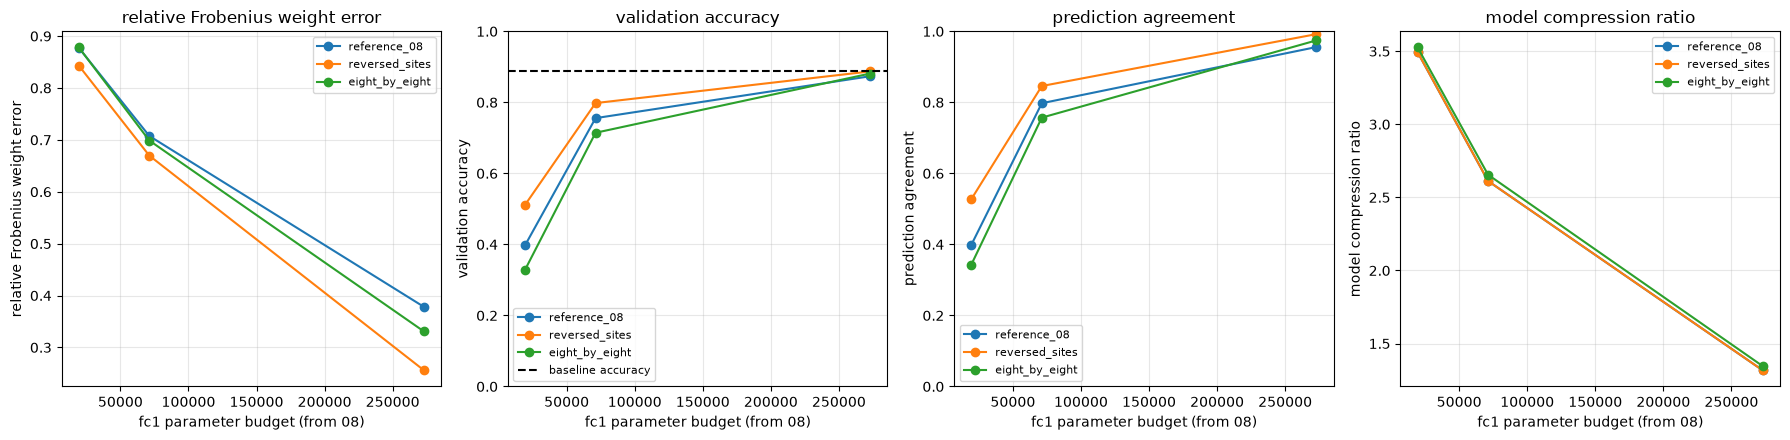

,selection_role,tensorization,requested_rank,reference_fc1_parameter_budget,relative_error,validation_accuracy,prediction_agreement,model_compression_ratio,fc1_parameters,budget_utilization
0,aggressive,eight_by_eight,12,19488,0.878087,0.3290,0.3434,3.525629,18080,0.927750
1,aggressive,reference_08,16,19488,0.877227,0.3978,0.3990,3.493265,19488,1.000000
2,aggressive,reversed_sites,16,19488,0.843037,0.5116,0.5276,3.493265,19488,1.000000
3,balanced,eight_by_eight,24,71232,0.698781,0.7144,0.7570,2.655167,67904,0.953279
4,balanced,reference_08,32,71232,0.707556,0.7556,0.7976,2.612090,71232,1.000000
5,balanced,reversed_sites,32,71232,0.669683,0.7980,0.8460,2.612090,71232,1.000000
6,conservative,eight_by_eight,48,273024,0.330753,0.8812,0.9746,1.345539,264320,0.968120
7,conservative,reference_08,64,273024,0.378123,0.8736,0.9558,1.316758,273024,1.000000
8,conservative,reversed_sites,64,273024,0.255853,0.8872,0.9922,1.316758,273024,1.000000


In [13]:
if EXERCISES_COMPLETED:
    # TODO 4: 指定した4つのsubplotを作り、figへFigureを代入する。
    # 横軸: 08由来の fc1 parameter 予算
    # 線: tensorization ごと
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    x_col = "reference_fc1_parameter_budget"

    plot_specs = [
        ("relative_error", "relative Frobenius weight error", False),
        ("validation_accuracy", "validation accuracy", True),
        ("prediction_agreement", "prediction agreement", False),
        ("model_compression_ratio", "model compression ratio", False),
    ]

    for ax, (y_col, ylabel, show_baseline) in zip(axes, plot_specs):
        for tensorization, group in df_tensorization_comparison.groupby(
            "tensorization", sort=False
        ):
            ordered = group.sort_values(x_col)
            ax.plot(
                ordered[x_col],
                ordered[y_col],
                marker="o",
                label=tensorization,
            )
        if show_baseline:
            ax.axhline(
                baseline_accuracy,
                color="black",
                linestyle="--",
                label="baseline accuracy",
            )
        if y_col in {"validation_accuracy", "prediction_agreement"}:
            ax.set_ylim(0.0, 1.0)
        ax.set_xlabel("fc1 parameter budget (from 08)")
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

    fig.tight_layout()
    plt.show()

    # 同じ指標を表でも確認する
    display(df_tensorization_comparison[[
        "selection_role",
        "tensorization",
        "requested_rank",
        "reference_fc1_parameter_budget",
        "relative_error",
        "validation_accuracy",
        "prediction_agreement",
        "model_compression_ratio",
        "fc1_parameters",
        "budget_utilization",
    ]].sort_values(
        ["selection_role", "tensorization"]
    ).reset_index(drop=True).round(6))
else:
    print("TODO 4の実装後にtrade-offを可視化します。")

## 10. 比較結果と次候補を保存する

`SAVE_RESULTS=True`のときだけ、全比較結果、各予算で選んだtensorization、図を保存します。モデルはこのNotebookでは保存しません。次Notebookでは保存したmodesとrankからbaselineを再圧縮し、fine-tuning前後を分けて評価します。

In [12]:
if EXERCISES_COMPLETED and SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)

    comparison_to_save = df_tensorization_comparison.copy()
    selected_to_save = df_selected_tensorizations.copy()
    tuple_columns = ["out_modes", "in_modes", "physical_sizes", "actual_ranks"]
    for column in tuple_columns:
        comparison_to_save[column] = comparison_to_save[column].map(str)
        selected_to_save[column] = selected_to_save[column].map(str)

    comparison_to_save.to_csv(
        results_dir / "tensorization_comparison.csv", index=False
    )
    selected_to_save.to_csv(
        results_dir / "selected_tensorizations.csv", index=False
    )
    df_tt_svd_cut_energy.to_csv(
        results_dir / "tt_svd_cut_energy.csv", index=False
    )
    fig.savefig(
        results_dir / "tensorization_tradeoffs.png",
        dpi=150,
        bbox_inches="tight",
    )
    fig_energy.savefig(
        results_dir / "tt_svd_cut_energy.png",
        dpi=150,
        bbox_inches="tight",
    )
    fig_global_energy.savefig(
        results_dir / "tt_svd_global_retained_energy.png",
        dpi=150,
        bbox_inches="tight",
    )
    print("saved to:", results_dir)
elif EXERCISES_COMPLETED:
    print("SAVE_RESULTS=False: 結果は保存していません。")
else:
    print("保存はTODO 1〜4の実装後に行います。")


saved to: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\09_pretrained_mlp_fc1_tt_tensorization_comparison


## 11. 次への接続

このNotebookを完成させると、

$$
\text{08で選んだparameter予算}
\rightarrow
\text{tensorizationごとのrank調整}
\rightarrow
\text{同一validationでの比較}
$$

ができます。次Notebookでは、09で選んだ構成をbaselineから再生成し、**TT置換直後**と**TT + fine-tuning後**を明確に分けて比較します。test setはfine-tuning後の最終候補を決めてから使用します。